# Abalone Age Prediction: Reviewed Experiment

Compare Linear Regression, Random Forest, and MLP using a fixed holdout and training-only cross-validation.

This reviewed copy retains the original model configurations and stored model outputs. Code has been statically checked, but the complete experiment has not been rerun. The age histogram was corrected and its stale output cleared. Restart the kernel and run all cells to reproduce results; package versions can affect numerical results.


## Data loading

The dataset contains 4,177 observations and eight predictors. Preserve the original measurements; do not correct suspicious values without evidence.


In [ ]:
import pandas as pd

columns = [
    "Sex",
    "Length",
    "Diameter",
    "Height",
    "Whole_weight",
    "Shucked_weight",
    "Viscera_weight",
    "Shell_weight",
    "Rings"
]

url = (
    "https://archive.ics.uci.edu/"
    "ml/machine-learning-databases/abalone/abalone.data"
)

df = pd.read_csv(url, header=None, names=columns)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (4177, 9)


,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


## Data audit

These descriptive checks were performed before the split. They are not a basis for fitting preprocessing parameters. All samples are retained.


In [ ]:
df.info()

print("\nMissing values per column:")
print(df.isna().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

print("\nSex category counts:")
print(df["Sex"].value_counts())

print("\nSummary statistics:")
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sex             4177 non-null   object 
 1   Length          4177 non-null   float64
 2   Diameter        4177 non-null   float64
 3   Height          4177 non-null   float64
 4   Whole_weight    4177 non-null   float64
 5   Shucked_weight  4177 non-null   float64
 6   Viscera_weight  4177 non-null   float64
 7   Shell_weight    4177 non-null   float64
 8   Rings           4177 non-null   int64  
dtypes: float64(7), int64(1), object(1)
memory usage: 293.8+ KB

Missing values per column:
Sex               0
Length            0
Diameter          0
Height            0
Whole_weight      0
Shucked_weight    0
Viscera_weight    0
Shell_weight      0
Rings             0
dtype: int64

Number of duplicate rows:
0

Sex category counts:
Sex
M    1528
I    1342
F    1307
Name: count, dtype: int64

Su

,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
count,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000
mean,0.523992,0.407881,0.139516,0.828742,0.359367,0.180594,0.238831,9.933684
std,0.120093,0.099240,0.041827,0.490389,0.221963,0.109614,0.139203,3.224169
min,0.075000,0.055000,0.000000,0.002000,0.001000,0.000500,0.001500,1.000000
25%,0.450000,0.350000,0.115000,0.441500,0.186000,0.093500,0.130000,8.000000
50%,0.545000,0.425000,0.140000,0.799500,0.336000,0.171000,0.234000,9.000000
75%,0.615000,0.480000,0.165000,1.153000,0.502000,0.253000,0.329000,11.000000
max,0.815000,0.650000,1.130000,2.825500,1.488000,0.760000,1.005000,29.000000


## Prediction target

Age = Rings + 1.5. Neither Rings nor Age is included in the predictors.


In [ ]:
df["Age"] = df["Rings"] + 1.5
X = df.drop(columns=["Rings", "Age"])
y = df["Age"]
print("Input features:", X.columns.tolist())
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
display(df[["Rings", "Age"]].head())

Input features: ['Sex', 'Length', 'Diameter', 'Height', 'Whole_weight', 'Shucked_weight', 'Viscera_weight', 'Shell_weight']
Feature matrix shape: (4177, 8)
Target shape: (4177,)


,Rings,Age
0,15,16.5
1,7,8.5
2,9,10.5
3,10,11.5
4,7,8.5


## Target distribution

Descriptive full-dataset plot. Integer bin edges cover every half-integer age, including the maximum age of 30.5 years.


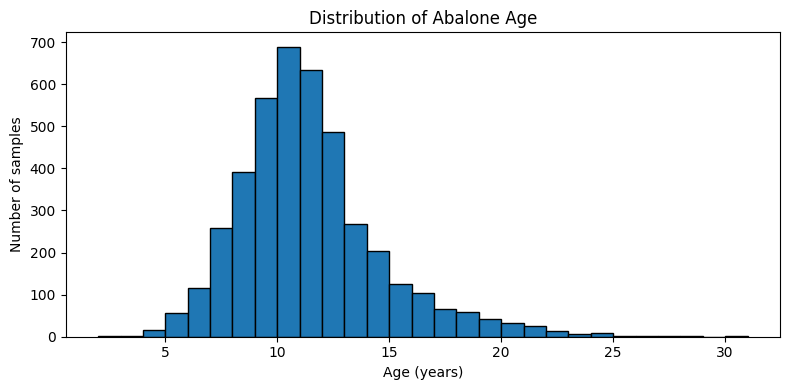

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))
plt.hist(
    y,
    bins=range(int(y.min()), int(y.max()) + 2),
    edgecolor="black"
)
plt.xlabel("Age (years)")
plt.ylabel("Number of samples")
plt.title("Distribution of Abalone Age")
plt.tight_layout()
plt.show()

## Fixed holdout split

Reserve 20% for final evaluation. All model selection uses the remaining 80%. The test set has already been inspected in the original experiment; do not use it to guide further tuning.


In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)
print("Training features shape:", X_train.shape)
print("Test features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Test target shape:", y_test.shape)

assert X_train.index.intersection(X_test.index).empty
assert len(X_train) + len(X_test) == len(X)
assert not {"Rings", "Age"}.intersection(X_train.columns)


Training features shape: (3341, 8)
Test features shape: (836, 8)
Training target shape: (3341,)
Test target shape: (836,)


## Linear regression pipeline

Categorical encoding and numerical scaling are fitted inside each outer training fold. Drop one category for the linear model with an intercept.


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

categorical_features = ["Sex"]
numeric_features = X_train.select_dtypes(include="number").columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(drop="first", handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numeric",
            StandardScaler(),
            numeric_features
        )
    ]
)

linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)

## Initial cross-validation

Use identical shuffled five-fold splits. Report mean fold MAE, mean fold RMSE, mean fold R2, and sample standard deviation of fold MAE. This standard deviation is not a confidence interval.


In [ ]:
import numpy as np

from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, cross_validate

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "MAE": "neg_mean_absolute_error",
    "MSE": "neg_mean_squared_error",
    "R2": "r2"
}
baseline_model = DummyRegressor(strategy="mean")
models = {
    "Mean Baseline": baseline_model,
    "Linear Regression": linear_model
}

results = []

for model_name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        error_score="raise"
    )
    fold_mae = -scores["test_MAE"]
    fold_rmse = np.sqrt(-scores["test_MSE"])
    fold_r2 = scores["test_R2"]
    results.append({
        "Model": model_name,
        "CV MAE": fold_mae.mean(),
        "CV MAE SD": fold_mae.std(ddof=1),
        "CV RMSE": fold_rmse.mean(),
        "CV R2": fold_r2.mean()
    })
cv_results = pd.DataFrame(results)
display(cv_results.round(3))

,Model,CV MAE,CV MAE SD,CV RMSE,CV R2
0,Mean Baseline,2.357,0.066,3.206,-0.002
1,Linear Regression,1.589,0.053,2.229,0.514


## Random forest pipeline

Numerical features pass through unchanged. Keep the original model settings for reproducibility.


In [ ]:
from sklearn.ensemble import RandomForestRegressor
forest_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numeric",
            "passthrough",
            numeric_features
        )
    ]
)

forest_model = Pipeline(
    steps=[
        ("preprocessor", forest_preprocessor),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [ ]:
forest_scores = cross_validate(
    forest_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    error_score="raise"
)

forest_mae = -forest_scores["test_MAE"]
forest_rmse = np.sqrt(-forest_scores["test_MSE"])
forest_r2 = forest_scores["test_R2"]

forest_result = pd.DataFrame([{
    "Model": "Random Forest",
    "CV MAE": forest_mae.mean(),
    "CV MAE SD": forest_mae.std(ddof=1),
    "CV RMSE": forest_rmse.mean(),
    "CV R2": forest_r2.mean()
}])
cv_results = pd.concat(
    [
        cv_results[
            cv_results["Model"] != "Random Forest"
        ],
        forest_result
    ],
    ignore_index=True
)

display(cv_results.round(3))

,Model,CV MAE,CV MAE SD,CV RMSE,CV R2
0,Mean Baseline,2.357,0.066,3.206,-0.002
1,Linear Regression,1.589,0.053,2.229,0.514
2,Random Forest,1.535,0.067,2.153,0.547


## MLP pipeline

Hidden layers use ReLU; the regression output uses identity activation. Early stopping monitors internal validation R2, not MAE. Scaling is fitted before the internal early-stopping split, so that internal validation set is not completely isolated from preprocessing. Outer validation and holdout rows remain excluded from preprocessing fits.


In [ ]:
from sklearn.neural_network import MLPRegressor

mlp_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numeric",
            StandardScaler(),
            numeric_features
        )
    ]
)

mlp_model = Pipeline(
    steps=[
        ("preprocessor", mlp_preprocessor),
        (
            "regressor",
            MLPRegressor(
                hidden_layer_sizes=(64, 32),
                activation="relu",
                solver="adam",
                alpha=0.001,
                learning_rate_init=0.001,
                max_iter=1000,
                early_stopping=True,
                validation_fraction=0.15,
                n_iter_no_change=30,
                random_state=42
            )
        )
    ]
)

In [ ]:
mlp_scores = cross_validate(
    mlp_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    error_score="raise"
)

mlp_mae = -mlp_scores["test_MAE"]
mlp_rmse = np.sqrt(-mlp_scores["test_MSE"])
mlp_r2 = mlp_scores["test_R2"]

mlp_result = pd.DataFrame([{
    "Model": "MLP",
    "CV MAE": mlp_mae.mean(),
    "CV MAE SD": mlp_mae.std(ddof=1),
    "CV RMSE": mlp_rmse.mean(),
    "CV R2": mlp_r2.mean()
}])

cv_results = pd.concat(
    [
        cv_results[cv_results["Model"] != "MLP"],
        mlp_result
    ],
    ignore_index=True
)

display(cv_results.round(3))

,Model,CV MAE,CV MAE SD,CV RMSE,CV R2
0,Mean Baseline,2.357,0.066,3.206,-0.002
1,Linear Regression,1.589,0.053,2.229,0.514
2,Random Forest,1.535,0.067,2.153,0.547
3,MLP,1.501,0.092,2.215,0.513


## Out-of-fold diagnostics: initial models

Each prediction comes from a model trained without that observation in its outer training fold. These diagnostics use initial, not tuned, models.


In [ ]:
from sklearn.model_selection import cross_val_predict

comparison_models = {
    "Linear Regression": linear_model,
    "Random Forest": forest_model,
    "MLP": mlp_model
}

oof_predictions = {}

for model_name, model in comparison_models.items():
    print(f"Generating out-of-fold predictions: {model_name}")

    oof_predictions[model_name] = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv
    )

print("Out-of-fold predictions are ready.")

Generating out-of-fold predictions: Linear Regression
Generating out-of-fold predictions: Random Forest
Generating out-of-fold predictions: MLP
Out-of-fold predictions are ready.


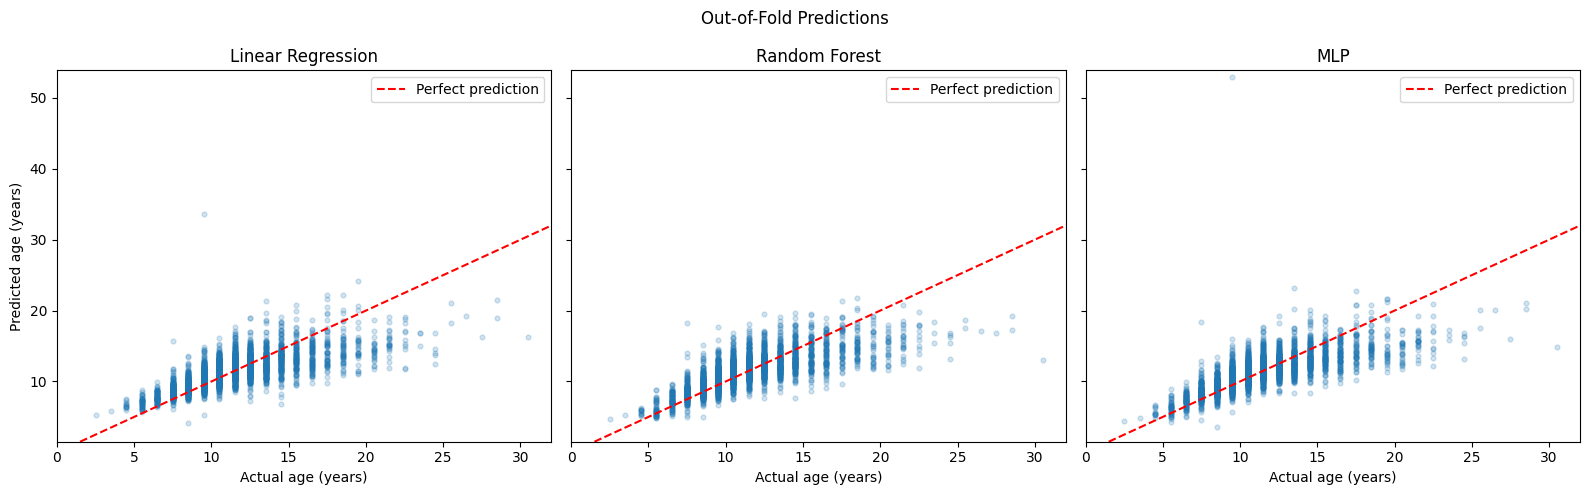

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

all_predictions = np.concatenate(
    list(oof_predictions.values())
)

lower = min(y_train.min(), all_predictions.min()) - 1
upper = max(y_train.max(), all_predictions.max()) + 1

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5),
    sharex=True,
    sharey=True
)

for ax, (model_name, predictions) in zip(
    axes, oof_predictions.items()
):
    ax.scatter(
        y_train,
        predictions,
        alpha=0.2,
        s=12
    )

    ax.plot(
        [lower, upper],
        [lower, upper],
        "r--",
        label="Perfect prediction"
    )

    ax.set_title(model_name)
    ax.set_xlabel("Actual age (years)")
    ax.set_xlim(0, 32)
    ax.set_ylim(lower, upper)
    ax.legend()

axes[0].set_ylabel("Predicted age (years)")

fig.suptitle("Out-of-Fold Predictions")
plt.tight_layout()
plt.show()

## Exploratory age groups

Use fixed descriptive age groups: below 10, 10 to below 15, and 15 or above. Bias means prediction minus actual age. These are not biological classifications.


In [ ]:
age_groups = pd.cut(
    y_train,
    bins=[-np.inf, 10, 15, np.inf],
    labels=["Below 10", "10 to below 15", "15 and above"],
    right=False
)

age_group_results = []

for model_name, predictions in oof_predictions.items():
    errors = predictions - y_train.to_numpy()

    evaluation = pd.DataFrame({
        "Age group": age_groups.to_numpy(),
        "Absolute error": np.abs(errors),
        "Squared error": errors ** 2,
        "Signed error": errors
    })

    summary = (
        evaluation
        .groupby("Age group", observed=True, sort=False)
        .agg(
            Samples=("Absolute error", "size"),
            MAE=("Absolute error", "mean"),
            MSE=("Squared error", "mean"),
            Bias=("Signed error", "mean")
        )
        .reset_index()
    )

    summary["RMSE"] = np.sqrt(summary.pop("MSE"))
    summary.insert(0, "Model", model_name)
    age_group_results.append(summary)

age_group_results = pd.concat(
    age_group_results,
    ignore_index=True
)

display(age_group_results.round(3))

,Model,Age group,Samples,MAE,Bias,RMSE
0,Linear Regression,10 to below 15,1824,1.311,0.122,1.702
1,Linear Regression,Below 10,1128,1.240,1.059,1.694
2,Linear Regression,15 and above,389,3.904,-3.594,4.562
3,Random Forest,10 to below 15,1824,1.274,0.221,1.674
4,Random Forest,Below 10,1128,1.248,0.925,1.644
5,Random Forest,15 and above,389,3.591,-3.286,4.348
6,MLP,10 to below 15,1824,1.213,0.137,1.606
7,MLP,Below 10,1128,1.224,0.914,2.014
8,MLP,15 and above,389,3.655,-3.408,4.340


## Largest errors

Inspect errors without deleting observations based on their target or prediction error.


In [ ]:
diagnostic_tables = {}

for model_name, predictions in oof_predictions.items():
    diagnostics = X_train.copy()

    diagnostics["Actual_age"] = y_train
    diagnostics["Predicted_age"] = predictions
    diagnostics["Error"] = (
        diagnostics["Predicted_age"]
        - diagnostics["Actual_age"]
    )
    diagnostics["Absolute_error"] = diagnostics["Error"].abs()

    diagnostic_tables[model_name] = diagnostics

    print(f"\nLargest prediction errors: {model_name}")
    display(
        diagnostics
        .nlargest(5, "Absolute_error")
        .round(3)
    )


Largest prediction errors: Linear Regression


,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Actual_age,Predicted_age,Error,Absolute_error
2051,F,0.455,0.355,1.130,0.594,0.332,0.116,0.134,9.5,33.633,24.133,24.133
480,F,0.700,0.585,0.185,1.808,0.706,0.322,0.475,30.5,16.231,-14.269,14.269
2305,F,0.550,0.415,0.135,0.775,0.302,0.179,0.260,24.5,12.513,-11.987,11.987
294,M,0.600,0.495,0.195,1.058,0.384,0.190,0.375,27.5,16.297,-11.203,11.203
678,F,0.450,0.380,0.165,0.816,0.250,0.192,0.265,24.5,13.704,-10.796,10.796



Largest prediction errors: Random Forest


,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Actual_age,Predicted_age,Error,Absolute_error
480,F,0.700,0.585,0.185,1.808,0.706,0.322,0.475,30.5,12.973,-17.527,17.527
2305,F,0.550,0.415,0.135,0.775,0.302,0.179,0.260,24.5,13.153,-11.347,11.347
2209,F,0.550,0.465,0.180,1.212,0.324,0.205,0.525,28.5,17.250,-11.250,11.250
2183,M,0.495,0.400,0.155,0.808,0.234,0.116,0.350,7.5,18.263,10.763,10.763
294,M,0.600,0.495,0.195,1.058,0.384,0.190,0.375,27.5,16.827,-10.673,10.673



Largest prediction errors: MLP


,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Actual_age,Predicted_age,Error,Absolute_error
2051,F,0.455,0.355,1.130,0.594,0.332,0.116,0.134,9.5,52.892,43.392,43.392
480,F,0.700,0.585,0.185,1.808,0.706,0.322,0.475,30.5,14.829,-15.671,15.671
294,M,0.600,0.495,0.195,1.058,0.384,0.190,0.375,27.5,15.985,-11.515,11.515
2305,F,0.550,0.415,0.135,0.775,0.302,0.179,0.260,24.5,13.143,-11.357,11.357
2183,M,0.495,0.400,0.155,0.808,0.234,0.116,0.350,7.5,18.395,10.895,10.895


In [ ]:
print("Training samples with non-positive height:")
display(X_train.loc[X_train["Height"] <= 0])

print("\nTraining samples with the largest height values:")
display(
    X_train
    .nlargest(10, "Height")
    .assign(Actual_age=y_train)
)

print("\nHeight distribution in the training set:")
display(
    X_train["Height"].describe(
        percentiles=[0.01, 0.50, 0.95, 0.99]
    )
)

Training samples with non-positive height:


,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight
3996,I,0.315,0.23,0.0,0.134,0.0575,0.0285,0.3505
1257,I,0.430,0.34,0.0,0.428,0.2065,0.0860,0.1150



Training samples with the largest height values:


,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Actual_age
2051,F,0.455,0.355,1.130,0.5940,0.3320,0.1160,0.1335,9.5
1417,M,0.705,0.565,0.515,2.2100,1.1075,0.4865,0.5120,11.5
2179,F,0.595,0.470,0.250,1.2830,0.4620,0.2475,0.4450,15.5
1763,M,0.775,0.630,0.250,2.7795,1.3485,0.7600,0.5780,13.5
1428,F,0.815,0.650,0.250,2.2550,0.8905,0.4200,0.7975,15.5
307,M,0.645,0.515,0.240,1.5415,0.4710,0.3690,0.5350,14.5
277,M,0.610,0.500,0.240,1.6420,0.5320,0.3345,0.6900,19.5
2161,F,0.715,0.565,0.240,2.1995,0.7245,0.4650,0.8850,18.5
1528,M,0.725,0.575,0.240,2.2100,1.3510,0.4130,0.5015,14.5
2212,F,0.595,0.495,0.235,1.3660,0.5065,0.2190,0.5200,14.5



Height distribution in the training set:


,Height
count,3341.000000
mean,0.139790
std,0.042514
min,0.000000
1%,0.047000
50%,0.140000
95%,0.200000
99%,0.220000
max,1.130000


## Height ablation: initial models

Remove Height without dropping rows. This is exploratory sensitivity analysis using initial configurations. Changing MLP input dimensions also changes initialization; the experiment does not isolate one observation causally.


In [ ]:
from sklearn.base import clone
numeric_features_no_height = [
    feature
    for feature in numeric_features
    if feature != "Height"
]

ablation_results = []
ablation_models = {}

for model_name, original_model in comparison_models.items():
    model = clone(original_model)

    transformers = [
        (name, transformer, numeric_features_no_height)
        if name == "numeric"
        else (name, transformer, columns)
        for name, transformer, columns
        in model.named_steps["preprocessor"].transformers
    ]

    model.set_params(
        preprocessor__transformers=transformers
    )

    ablation_models[model_name] = model

    print(f"Evaluating without Height: {model_name}")

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        error_score="raise"
    )

    fold_mae = -scores["test_MAE"]
    fold_rmse = np.sqrt(-scores["test_MSE"])

    ablation_results.append({
        "Model": model_name,
        "CV MAE without Height": fold_mae.mean(),
        "CV RMSE without Height": fold_rmse.mean(),
        "CV R2 without Height": scores["test_R2"].mean()
    })

ablation_results = pd.DataFrame(ablation_results)

height_comparison = (
    cv_results[
        cv_results["Model"].isin(comparison_models)
    ][["Model", "CV MAE", "CV RMSE", "CV R2"]]
    .merge(ablation_results, on="Model")
)

height_comparison["MAE change"] = (
    height_comparison["CV MAE without Height"]
    - height_comparison["CV MAE"]
)

height_comparison["RMSE change"] = (
    height_comparison["CV RMSE without Height"]
    - height_comparison["CV RMSE"]
)

display(height_comparison.round(3))

Evaluating without Height: Linear Regression
Evaluating without Height: Random Forest
Evaluating without Height: MLP


,Model,CV MAE,CV RMSE,CV R2,CV MAE without Height,CV RMSE without Height,CV R2 without Height,MAE change,RMSE change
0,Linear Regression,1.589,2.229,0.514,1.593,2.207,0.525,0.004,-0.021
1,Random Forest,1.535,2.153,0.547,1.549,2.169,0.540,0.014,0.016
2,MLP,1.501,2.215,0.513,1.509,2.108,0.566,0.008,-0.107


In [ ]:
mlp_no_height_oof = cross_val_predict(
    ablation_models["MLP"],
    X_train,
    y_train,
    cv=cv
)

height_diagnostics = X_train[["Height"]].copy()
height_diagnostics["Actual_age"] = y_train
height_diagnostics["Prediction_with_Height"] = oof_predictions["MLP"]
height_diagnostics["Prediction_without_Height"] = mlp_no_height_oof

height_diagnostics["Absolute_error_with_Height"] = np.abs(
    height_diagnostics["Prediction_with_Height"]
    - height_diagnostics["Actual_age"]
)

height_diagnostics["Absolute_error_without_Height"] = np.abs(
    height_diagnostics["Prediction_without_Height"]
    - height_diagnostics["Actual_age"]
)

print("Samples with the largest original MLP errors:")
display(
    height_diagnostics
    .nlargest(5, "Absolute_error_with_Height")
    .round(3)
)

print("\nSamples with the largest MLP errors after removing Height:")
display(
    height_diagnostics
    .nlargest(5, "Absolute_error_without_Height")
    .round(3)
)

Samples with the largest original MLP errors:


,Height,Actual_age,Prediction_with_Height,Prediction_without_Height,Absolute_error_with_Height,Absolute_error_without_Height
2051,1.130,9.5,52.892,9.122,43.392,0.378
480,0.185,30.5,14.829,13.845,15.671,16.655
294,0.195,27.5,15.985,15.833,11.515,11.667
2305,0.135,24.5,13.143,13.498,11.357,11.002
2183,0.155,7.5,18.395,17.659,10.895,10.159



Samples with the largest MLP errors after removing Height:


,Height,Actual_age,Prediction_with_Height,Prediction_without_Height,Absolute_error_with_Height,Absolute_error_without_Height
480,0.185,30.5,14.829,13.845,15.671,16.655
294,0.195,27.5,15.985,15.833,11.515,11.667
2305,0.135,24.5,13.143,13.498,11.357,11.002
673,0.150,22.5,12.217,11.553,10.283,10.947
2108,0.225,28.5,20.222,18.184,8.278,10.316


## Limited random forest search

Six configurations, selected by mean validation MAE. GridSearchCV refits the selected configuration on the full training set. Selected CV scores may be optimistic because these folds were used for selection.


In [ ]:
from sklearn.model_selection import GridSearchCV
forest_param_grid = {
    "regressor__max_depth": [None, 10],
    "regressor__min_samples_leaf": [1, 3, 5]
}

forest_search = GridSearchCV(
    estimator=clone(forest_model),
    param_grid=forest_param_grid,
    scoring=scoring,
    refit="MAE",
    cv=cv,
    n_jobs=1,
    return_train_score=False,
    error_score="raise"
)

forest_search.fit(X_train, y_train)

print("Best parameters:")
print(forest_search.best_params_)

print(
    "\nBest mean CV MAE:",
    round(-forest_search.best_score_, 3)
)

Best parameters:
{'regressor__max_depth': 10, 'regressor__min_samples_leaf': 5}

Best mean CV MAE: 1.506


In [ ]:
forest_tuning_results = pd.DataFrame(
    forest_search.cv_results_
)

forest_tuning_summary = pd.DataFrame({
    "Max depth": forest_tuning_results[
        "param_regressor__max_depth"
    ],
    "Min samples per leaf": forest_tuning_results[
        "param_regressor__min_samples_leaf"
    ],
    "CV MAE": -forest_tuning_results["mean_test_MAE"],
    "CV RMSE": [
        np.sqrt(
            -forest_tuning_results[
                [f"split{i}_test_MSE" for i in range(5)]
            ].iloc[row].to_numpy(dtype=float)
        ).mean()
        for row in range(len(forest_tuning_results))
    ],
    "CV R2": forest_tuning_results["mean_test_R2"]
})

display(
    forest_tuning_summary
    .sort_values("CV MAE")
    .reset_index(drop=True)
    .round(3)
)

,Max depth,Min samples per leaf,CV MAE,CV RMSE,CV R2
0,10,5,1.506,2.126,0.558
1,10,3,1.508,2.130,0.557
2,None,5,1.511,2.129,0.557
3,10,1,1.515,2.138,0.553
4,None,3,1.519,2.137,0.554
5,None,1,1.535,2.153,0.547


## Limited MLP search

Six configurations, selected by MAE with one fixed seed. Results do not establish seed robustness or a general advantage of deeper networks.


In [ ]:
mlp_param_grid = {
    "regressor__hidden_layer_sizes": [
        (32,),
        (64, 32),
        (64, 32, 16)
    ],
    "regressor__alpha": [0.001, 0.01]
}

mlp_search = GridSearchCV(
    estimator=clone(mlp_model),
    param_grid=mlp_param_grid,
    scoring=scoring,
    refit="MAE",
    cv=cv,
    n_jobs=1,
    return_train_score=False,
    error_score="raise"
)

mlp_search.fit(X_train, y_train)

print("Best parameters:")
print(mlp_search.best_params_)

print(
    "\nBest mean CV MAE:",
    round(-mlp_search.best_score_, 3)
)

Best parameters:
{'regressor__alpha': 0.001, 'regressor__hidden_layer_sizes': (64, 32, 16)}

Best mean CV MAE: 1.483


In [ ]:
mlp_tuning_results = pd.DataFrame(
    mlp_search.cv_results_
)

mse_columns = [
    f"split{i}_test_MSE"
    for i in range(cv.get_n_splits())
]

mlp_tuning_summary = pd.DataFrame({
    "Hidden layers": mlp_tuning_results[
        "param_regressor__hidden_layer_sizes"
    ],
    "Alpha": mlp_tuning_results[
        "param_regressor__alpha"
    ],
    "CV MAE": -mlp_tuning_results["mean_test_MAE"],
    "CV RMSE": np.sqrt(
        -mlp_tuning_results[mse_columns].to_numpy(dtype=float)
    ).mean(axis=1),
    "CV R2": mlp_tuning_results["mean_test_R2"]
})

display(
    mlp_tuning_summary
    .sort_values("CV MAE")
    .reset_index(drop=True)
    .round(3)
)

,Hidden layers,Alpha,CV MAE,CV RMSE,CV R2
0,"(64, 32, 16)",0.001,1.483,2.120,0.560
1,"(64, 32, 16)",0.010,1.489,2.123,0.559
2,"(64, 32)",0.001,1.501,2.215,0.513
3,"(64, 32)",0.010,1.503,2.195,0.524
4,"(32,)",0.001,1.507,2.118,0.562
5,"(32,)",0.010,1.508,2.120,0.561


## Final holdout evaluation

Freeze configurations before evaluation. Refit each model using the training set; MLP still reserves an internal early-stopping subset. This section reproduces the already-completed final evaluation, not a new independent test.


In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

final_models = {
    "Mean Baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": clone(linear_model),
    "Random Forest": clone(forest_search.best_estimator_),
    "MLP": clone(mlp_search.best_estimator_)
}

test_results = []
test_predictions = {}

for model_name, model in final_models.items():
    print(f"Fitting and evaluating: {model_name}")

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    test_predictions[model_name] = predictions

    test_results.append({
        "Model": model_name,
        "Test MAE": mean_absolute_error(y_test, predictions),
        "Test RMSE": np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        "Test R2": r2_score(y_test, predictions)
    })

test_results = pd.DataFrame(test_results)

display(test_results.round(3))

Fitting and evaluating: Mean Baseline
Fitting and evaluating: Linear Regression
Fitting and evaluating: Random Forest
Fitting and evaluating: MLP


,Model,Test MAE,Test RMSE,Test R2
0,Mean Baseline,2.385,3.291,-0.000
1,Linear Regression,1.593,2.212,0.548
2,Random Forest,1.541,2.207,0.550
3,MLP,1.522,2.133,0.580


## Export results

Save numerical outputs without rounding. Version and parameter metadata describe this execution, not the historical environment of the original outputs.


In [ ]:
from pathlib import Path

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

cv_results.to_csv(
    results_dir / "initial_cv_results.csv",
    index=False
)

forest_tuning_summary.to_csv(
    results_dir / "random_forest_tuning_results.csv",
    index=False
)

mlp_tuning_summary.to_csv(
    results_dir / "mlp_tuning_results.csv",
    index=False
)

height_comparison.to_csv(
    results_dir / "height_ablation_results.csv",
    index=False
)

test_results.to_csv(
    results_dir / "final_test_results.csv",
    index=False
)

prediction_table = pd.DataFrame({
    "Sample_index": y_test.index,
    "Actual_age": y_test.to_numpy(),
    **test_predictions
})

prediction_table.to_csv(
    results_dir / "final_test_predictions.csv",
    index=False
)

print("Results saved to:", results_dir.resolve())

import platform
import sklearn

metadata = {
    "python": platform.python_version(),
    "scikit_learn": sklearn.__version__,
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "random_state": 42,
    "test_size": 0.2,
    "cv_folds": cv.get_n_splits(),
    "selection_metric": "MAE",
    "forest_best_params": forest_search.best_params_,
    "mlp_best_params": mlp_search.best_params_,
    "final_mlp_iterations": int(final_models["MLP"].named_steps["regressor"].n_iter_),
    "final_mlp_iteration_limit": int(final_models["MLP"].named_steps["regressor"].max_iter)
}

import json
(results_dir / "run_metadata.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)
pd.DataFrame({
    "Sample_index": X.index,
    "Split": ["train" if index in X_train.index else "test" for index in X.index]
}).to_csv(results_dir / "split_indices.csv", index=False)


Results saved to: /content/results


## Holdout subgroup analysis

Use the same age boundaries as in training diagnostics. Compare errors and sample counts. Do not tune using these holdout findings.


In [ ]:
test_age_groups = pd.cut(
    y_test,
    bins=[-np.inf, 10, 15, np.inf],
    labels=["Below 10", "10 to below 15", "15 and above"],
    right=False
)

test_group_tables = []

for model_name in comparison_models:
    predictions = test_predictions[model_name]
    errors = predictions - y_test.to_numpy()

    evaluation = pd.DataFrame({
        "Age group": test_age_groups.to_numpy(),
        "Absolute error": np.abs(errors),
        "Squared error": errors ** 2,
        "Signed error": errors
    })

    summary = (
        evaluation
        .groupby("Age group", observed=True, sort=False)
        .agg(
            Samples=("Absolute error", "size"),
            MAE=("Absolute error", "mean"),
            MSE=("Squared error", "mean"),
            Bias=("Signed error", "mean")
        )
        .reset_index()
    )

    summary["RMSE"] = np.sqrt(summary.pop("MSE"))
    summary.insert(0, "Model", model_name)
    test_group_tables.append(summary)

test_age_group_results = pd.concat(
    test_group_tables,
    ignore_index=True
)

display(test_age_group_results.round(3))

test_age_group_results.to_csv(
    results_dir / "test_age_group_results.csv",
    index=False
)

,Model,Age group,Samples,MAE,Bias,RMSE
0,Linear Regression,10 to below 15,456,1.326,0.213,1.719
1,Linear Regression,Below 10,279,1.235,0.993,1.610
2,Linear Regression,15 and above,101,3.791,-3.628,4.470
3,Random Forest,10 to below 15,456,1.271,0.332,1.664
4,Random Forest,Below 10,279,1.127,0.820,1.436
5,Random Forest,15 and above,101,3.902,-3.699,4.704
6,MLP,10 to below 15,456,1.231,0.244,1.598
7,MLP,Below 10,279,1.203,0.914,1.581
8,MLP,15 and above,101,3.712,-3.522,4.385


## Report figure

Bias is signed error, not an estimate of statistical estimator bias. These plots show descriptive results without confidence intervals.


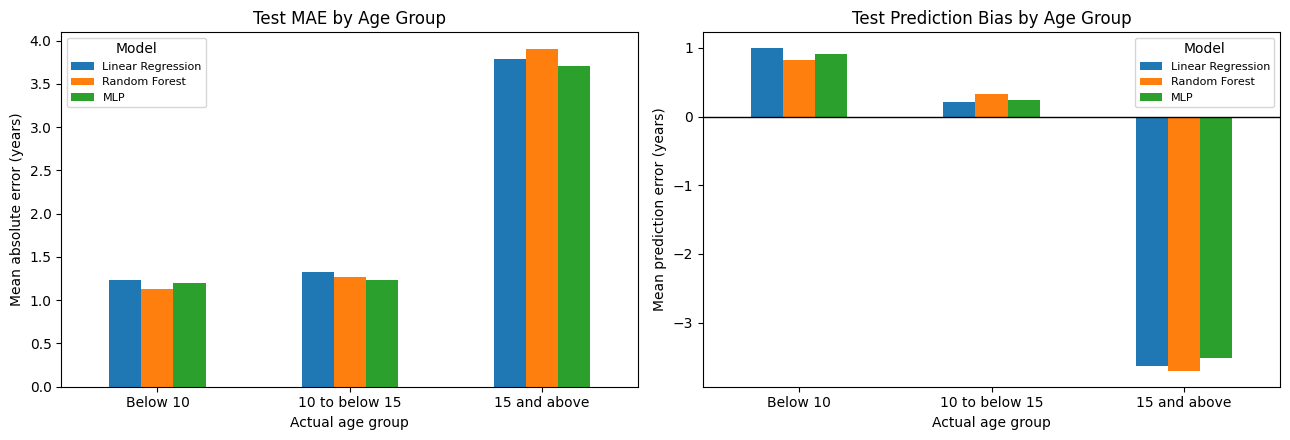

In [ ]:
age_order = [
    "Below 10",
    "10 to below 15",
    "15 and above"
]

model_order = [
    "Linear Regression",
    "Random Forest",
    "MLP"
]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, metric, title, ylabel in [
    (
        axes[0],
        "MAE",
        "Test MAE by Age Group",
        "Mean absolute error (years)"
    ),
    (
        axes[1],
        "Bias",
        "Test Prediction Bias by Age Group",
        "Mean prediction error (years)"
    )
]:
    plot_data = (
        test_age_group_results
        .pivot(index="Age group", columns="Model", values=metric)
        .reindex(index=age_order, columns=model_order)
    )

    plot_data.plot.bar(ax=ax, rot=0)

    ax.set_title(title)
    ax.set_xlabel("Actual age group")
    ax.set_ylabel(ylabel)
    ax.legend(title="Model", fontsize=8)

axes[1].axhline(0, color="black", linewidth=1)

plt.tight_layout()

fig.savefig(
    results_dir / "test_performance_by_age_group.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()